# Простые модели и сезонное обучение

LFPG 09L, погожие дни 2025 года. Ridge, Huber, ElasticNet и Polynomial Ridge учат поправку к прогнозу с постоянной вертикальной скоростью. Горизонт 30 ± 3 секунды, девять прежних причинных признаков, наблюдения до барометрического прокси 300 ft. Меток ухода на второй круг здесь нет.

Последний выбранный день каждого сезона оставлен для теста, предыдущий для валидации, остальные для обучения. Идентификатор борта не является признаком; борта могут повторяться между днями. Параметры выбираются по валидации. Каждый заход имеет одинаковый суммарный обучающий вес

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

base = Path.cwd()
days = pd.read_csv(base / 'reports/selected_days.csv')
metrics = pd.read_csv(base / 'reports/model_metrics.csv')
learning = pd.read_csv(base / 'reports/learning_curve.csv')
table = pd.read_csv(base / 'reports/final_table.csv', index_col=0)
season_labels = {'winter': 'Зима', 'spring': 'Весна', 'summer': 'Лето', 'autumn': 'Осень'}
seasons = [s for s in season_labels if s in table.columns]
labels = [season_labels[s] for s in seasons]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
display(days.groupby(['season', 'split']).agg(Дней=('day', 'size'),
             Заходов=('approaches', 'sum'), Пар=('examples', 'sum')))


Дней  Заходов   Пар
season split                          
autumn test           1       14  1074
       train          3       48  3401
       validation     1       14  1088

## Итоговая таблица

Обучение на всех доступных обучающих днях выбранных сезонов. Ошибка MAE усредняется сначала внутри каждого захода, затем между заходами; единица измерения ft. Проверочные дни одинаковы для всех моделей

In [2]:
shown = table.rename(columns=dict(zip(seasons + ['all'], labels + ['Все сезоны'])))
display(shown.style.format('{:.2f}').highlight_min(axis=0, color='#DDEFE8'))


,Осень,Все сезоны
model,,
Ridge,16.44,16.44
Polynomial Ridge,17.46,17.46
Huber,16.41,16.41
ElasticNet,16.25,16.25
Constant vertical rate,56.66,56.66


## Влияние числа дней

Четыре модели используют одни и те же проверочные дни при добавлении обучающих дней по порядку дат. Берем все пригодные примеры включенных дней. Это первое сравнение: одновременно растут число примеров и разнообразие дней. Параметры фиксируются после выбора по валидации полного обучающего набора сезона

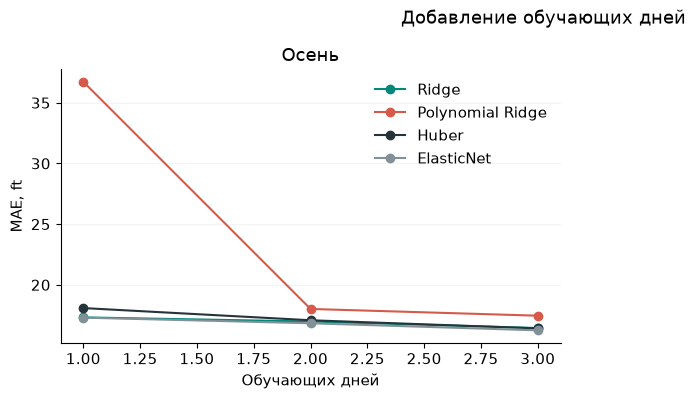

,season,model,train_days,train_approaches,macro_mae_ft
0,autumn,Ridge,1,15,17.316364
1,autumn,Polynomial Ridge,1,15,36.733861
2,autumn,Huber,1,15,18.083614
3,autumn,ElasticNet,1,15,17.295408
4,autumn,Ridge,2,34,16.976487
5,autumn,Polynomial Ridge,2,34,18.011400
6,autumn,Huber,2,34,17.079747
7,autumn,ElasticNet,2,34,16.831605
8,autumn,Ridge,3,48,16.437457
9,autumn,Polynomial Ridge,3,48,17.455498


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, season, label in zip(axes.flat, seasons, labels):
    subset = learning.loc[learning.season.eq(season) & learning.converged]
    for model, color in [('Ridge', '#00897B'), ('Polynomial Ridge', '#D65A4A'),
                         ('Huber', '#25343B'), ('ElasticNet', '#829198')]:
        values = subset.loc[subset.model.eq(model)].sort_values('train_days')
        ax.plot(values.train_days, values.macro_mae_ft, marker='o', color=color, label=model)
    ax.set(title=label, xlabel='Обучающих дней', ylabel='MAE, ft')
    ax.grid(axis='y', alpha=.15)
axes[0, 0].legend(frameon=False)
for ax in list(axes.flat)[len(seasons):]:
    ax.set_visible(False)
fig.suptitle('Добавление обучающих дней')
fig.tight_layout()
fig.savefig(base / 'figures/02_learning.png', dpi=180, bbox_inches='tight')
plt.show()
display(learning[['season', 'model', 'train_days', 'train_approaches', 'macro_mae_ft']])


## Перенос между сезонами

Для Ridge показана ошибка при обучении в одном сезоне и проверке на отложенных днях всех сезонов. Параметры выбирались только по валидации обучающего сезона. Это сравнение переноса между сезонными группами на отложенных днях

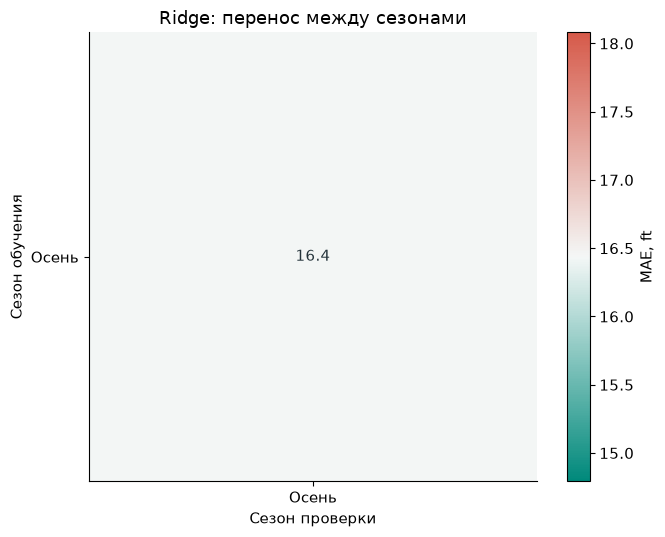

In [4]:
transfer = metrics.loc[metrics.model.eq('Ridge') & metrics.source.isin(seasons)
                       & metrics.target.isin(seasons)].pivot(index='source', columns='target', values='macro_mae_ft')
transfer = transfer.reindex(index=seasons, columns=seasons)
fig, ax = plt.subplots(figsize=(7, 5.5))
cmap = LinearSegmentedColormap.from_list('seasonal', ['#00897B', '#F4F7F6', '#D65A4A'])
image = ax.imshow(transfer.to_numpy(), cmap=cmap)
ax.set(xticks=range(len(seasons)), xticklabels=labels, yticks=range(len(seasons)), yticklabels=labels,
       xlabel='Сезон проверки', ylabel='Сезон обучения', title='Ridge: перенос между сезонами')
for row in range(len(seasons)):
    for column in range(len(seasons)):
        ax.text(column, row, f'{transfer.iloc[row, column]:.1f}', ha='center', va='center', color='#25343B')
fig.colorbar(image, ax=ax, label='MAE, ft')
fig.tight_layout()
fig.savefig(base / 'figures/02_transfer.png', dpi=180, bbox_inches='tight')
plt.show()
